# N01: Power (MDE) and TOST equivalence for Study 1 reclaim returns

Specification: `PREREG/N01_power.md` (committed before this notebook ran).
All logic is in `src/power.py`; this notebook only calls it and plots.

**Hindsight status:** Study 1 data were already seen. N01 re-expresses them;
it is not new evidence.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "power.py").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import power as P

pd.set_option("display.width", 160)
events = {ix: P.load_study1_events(ix) for ix in ("NDX", "SPX")}

## Anchor checks (stop if any fails)

In [2]:
P.check_anchors(events)

,index,item,got,reported,ok
0,NDX,reclaimed count,37.00000,37.000,True
1,NDX,mean r20,0.01542,0.015,True
2,NDX,mean r60,0.04592,0.046,True
3,NDX,mean r120,0.11594,0.116,True
4,SPX,reclaimed count,67.00000,67.000,True
5,SPX,mean r20,0.00525,0.005,True
6,SPX,mean r60,0.02027,0.020,True
7,SPX,mean r120,0.03749,0.037,True


## MDE at 80% power (one-sided t, alpha 0.05; 10,000 simulations, seed 7)

In [3]:
mde = P.mde_table(events)
print(P.format_mde_table(mde).to_markdown(index=False))

| Index   | Horizon   |   n |   SD (pts) | Reclaim mean   | Benchmark   |   MDE sim (pts) |   MDE exact (pts) |   MDE / SD |   MDE @0.00139 (pts) |
|:--------|:----------|----:|-----------:|:---------------|:------------|----------------:|------------------:|-----------:|---------------------:|
| NDX     | r20       |  36 |       8.06 | +1.5%          | +1.6%       |            3.42 |              3.41 |       0.42 |                 5.5  |
| NDX     | r60       |  36 |      18.03 | +4.6%          | +5.0%       |            7.67 |              7.62 |       0.43 |                12.31 |
| NDX     | r120      |  36 |      26.47 | +11.6%         | +10.0%      |           11.23 |             11.19 |       0.42 |                18.07 |
| SPX     | r20       |  67 |       6.35 | +0.5%          | +0.7%       |            1.95 |              1.95 |       0.31 |                 3.08 |
| SPX     | r60       |  67 |       9.54 | +2.0%          | +1.9%       |            2.93 |              2.93 | 

## TOST equivalence vs the drawdown-matched mean (bounds +/-2 and +/-5 points, alpha 0.05)

In [4]:
tost = P.tost_table(events)
show = tost[["index", "horizon", "n", "benchmark_mean", "diff", "ci90_lo", "ci90_hi",
             "bound", "p_lower", "p_upper", "p_tost", "equivalent", "bh_q", "bh_equivalent_q10"]]
print(show.to_markdown(index=False, floatfmt=".4f"))

| index   | horizon   |   n |   benchmark_mean |    diff |   ci90_lo |   ci90_hi |   bound |   p_lower |   p_upper |   p_tost | equivalent   |   bh_q | bh_equivalent_q10   |
|:--------|:----------|----:|-----------------:|--------:|----------:|----------:|--------:|----------:|----------:|---------:|:-------------|-------:|:--------------------|
| NDX     | r20       |  36 |           0.0160 | -0.0006 |   -0.0233 |    0.0221 |  0.0200 |    0.0787 |    0.0673 |   0.0787 | False        | 0.1180 | False               |
| NDX     | r20       |  36 |           0.0160 | -0.0006 |   -0.0233 |    0.0221 |  0.0500 |    0.0004 |    0.0003 |   0.0004 | True         | 0.0016 | True                |
| NDX     | r60       |  36 |           0.0500 | -0.0041 |   -0.0549 |    0.0467 |  0.0200 |    0.2999 |    0.2142 |   0.2999 | False        | 0.3271 | False               |
| NDX     | r60       |  36 |           0.0500 | -0.0041 |   -0.0549 |    0.0467 |  0.0500 |    0.0678 |    0.0403 |   0.0678 | Fa

In [5]:
out = P.save_outputs(mde, tost)
ledger = P.update_ledger(tost)
print(f"saved to {out.relative_to(ROOT)}; ledger rows for N01: {(ledger['family'] == 'N01_TOST').sum()}")

saved to results/N01_power; ledger rows for N01: 12


## DESCRIPTIVE: MDE under a cluster bootstrap by calendar year (no tests)

PREREG/N01_power.md addendum. Resamples whole calendar years (B = 5,000,
seed 7) to show how optimistic the iid MDEs are. Not a hypothesis test.

In [6]:
cl_mde = P.cluster_mde_table(events)
print(P.format_cluster_mde_table(cl_mde).to_markdown(index=False))

| Index   | Horizon   |   n |   Years (G) |   SE iid (pts) |   SE cluster (pts) |   SE ratio |   MDE iid z (pts) |   MDE cluster z (pts) |   MDE cluster t(G-1) (pts) |
|:--------|:----------|----:|------------:|---------------:|-------------------:|-----------:|------------------:|----------------------:|---------------------------:|
| NDX     | r20       |  36 |          20 |           1.34 |               1.37 |       1.02 |              3.34 |                  3.41 |                       3.55 |
| NDX     | r60       |  36 |          20 |           3.01 |               4.12 |       1.37 |              7.47 |                 10.24 |                      10.67 |
| NDX     | r120      |  36 |          20 |           4.41 |               6.28 |       1.42 |             10.97 |                 15.61 |                      16.26 |
| SPX     | r20       |  67 |          37 |           0.78 |               0.65 |       0.84 |              1.93 |                  1.62 |                      

## Charts

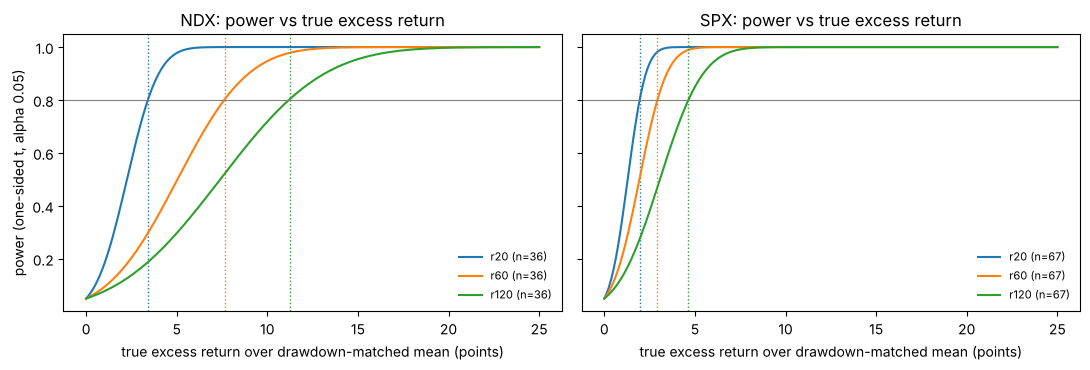

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, ix in zip(axes, ["NDX", "SPX"]):
    g = mde[mde["index"] == ix]
    for k, (_, r) in enumerate(g.iterrows()):
        d = np.linspace(0, 0.25, 200)
        ax.plot(d * 100, P.power_curve(int(r["n"]), r["sd"], d), label=f"{r['horizon']} (n={r['n']})")
        ax.axvline(r["mde_sim"] * 100, ls=":", lw=1, color=f"C{k}")
    ax.axhline(0.8, color="grey", lw=0.8)
    ax.set_title(f"{ix}: power vs true excess return")
    ax.set_xlabel("true excess return over drawdown-matched mean (points)")
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("power (one-sided t, alpha 0.05)")
fig.tight_layout()

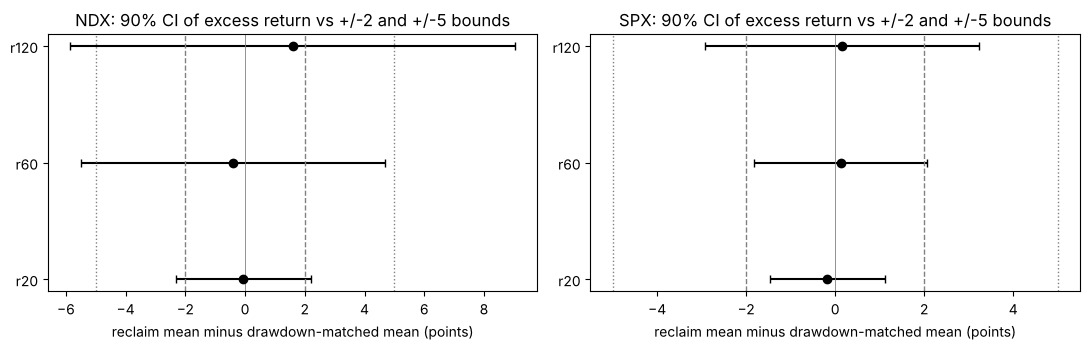

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=False)
for ax, ix in zip(axes, ["NDX", "SPX"]):
    g = tost[(tost["index"] == ix) & (tost["bound"] == 0.02)].reset_index(drop=True)
    y = np.arange(len(g))
    ax.errorbar(g["diff"] * 100, y, xerr=[(g["diff"] - g["ci90_lo"]) * 100, (g["ci90_hi"] - g["diff"]) * 100],
                fmt="o", color="k", capsize=3)
    for b, ls in [(2, "--"), (5, ":")]:
        for s in (-1, 1):
            ax.axvline(s * b, ls=ls, color="grey", lw=1)
    ax.axvline(0, color="grey", lw=0.6)
    ax.set_yticks(y, g["horizon"])
    ax.set_title(f"{ix}: 90% CI of excess return vs +/-2 and +/-5 bounds")
    ax.set_xlabel("reclaim mean minus drawdown-matched mean (points)")
fig.tight_layout()